## Objectives

In this self-study lab you will

- run gradient descent on all ten features of the diabetes data and see why raw features make it slow;
- implement min-max, mean and z-score normalisation;
- see that scaling changes the units of the features, but not the fitted model;
- make predictions for new examples with the stored training statistics;
- use learning curves to check gradient descent and to choose the learning rate $\alpha$;
- do the same scaling with scikit-learn's `StandardScaler`.

## Tools

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_diabetes
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler

np.set_printoptions(precision=3, suppress=True)   # print arrays with 3 decimals, no e-notation

## Problem statement

We use all ten features of the diabetes data: age, sex, BMI, blood pressure (BP) and six blood measurements S1 to S6 (for example, S1 is the total cholesterol). The target is again the disease progression after one year.

In [2]:
diabetes = load_diabetes(scaled=False)
X_train, y_train = diabetes.data, diabetes.target
feature_names = diabetes.feature_names
m, n = X_train.shape
print(f"m = {m} examples, n = {n} features\n")

print(f"{'feature':>8s} {'min':>8s} {'max':>8s} {'mean':>8s} {'std':>8s}")
for j, name in enumerate(feature_names):
    col = X_train[:, j]
    print(f"{name:>8s} {col.min():8.2f} {col.max():8.2f} {col.mean():8.2f} {col.std():8.2f}")

m = 442 examples, n = 10 features

 feature      min      max     mean      std
     age    19.00    79.00    48.52    13.09
     sex     1.00     2.00     1.47     0.50
     bmi    18.00    42.20    26.38     4.41
      bp    62.00   133.00    94.65    13.82
      s1    97.00   301.00   189.14    34.57
      s2    41.60   242.40   115.44    30.38
      s3    22.00    99.00    49.79    12.92
      s4     2.00     9.09     4.07     1.29
      s5     3.26     6.11     4.64     0.52
      s6    58.00   124.00    91.26    11.48


The features live on very different scales: `sex` takes the values 1 and 2, `s5` lies between about 3 and 6, while `s1` goes up to 301. Plotting every feature against the target gives a first impression of the data.

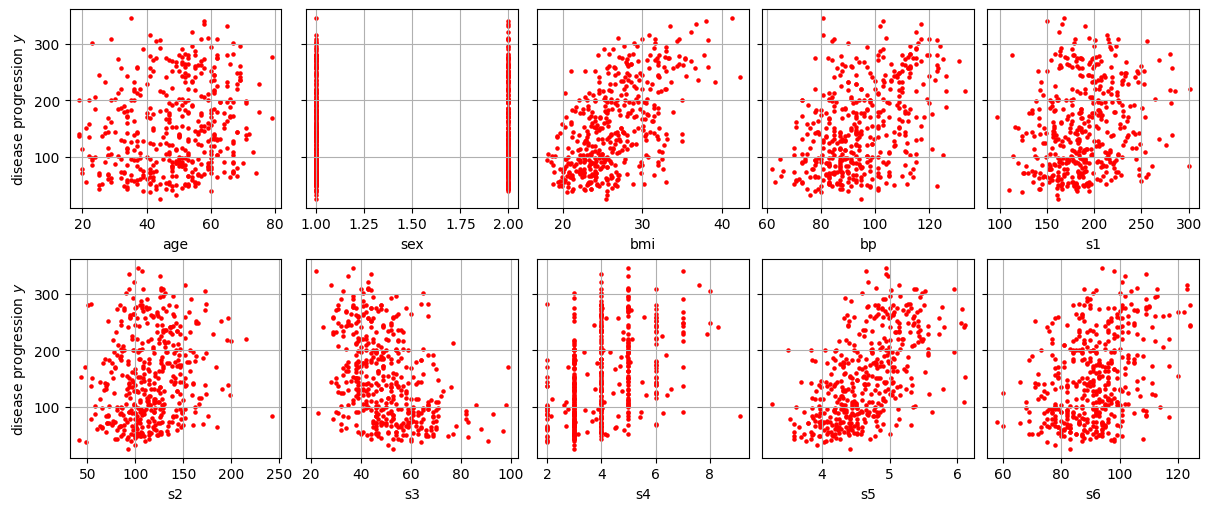

In [3]:
fig, ax = plt.subplots(2, 5, figsize=(12, 5), sharey=True, constrained_layout=True)
for j, a in enumerate(ax.flat):
    a.scatter(X_train[:, j], y_train, s=5, c='r')
    a.set_xlabel(feature_names[j])
    a.grid(True)
ax[0, 0].set_ylabel('disease progression $y$')
ax[1, 0].set_ylabel('disease progression $y$')
plt.show()

## Tools from Lab 3

We reuse the vectorised cost and gradient descent from Lab 3, and compute the exact minimum $J_{\min}$ with scikit-learn as a reference.

In [4]:
def compute_cost(X, y, w, b):
    """Squared-error cost J(w,b)."""
    err = X @ w + b - y
    return np.sum(err ** 2) / (2 * X.shape[0])

def gradient_descent(X, y, alpha=0.1, n_iters=1000):
    """Batch gradient descent from w = 0, b = 0; returns w, b and the cost history."""
    m, n = X.shape
    w, b = np.zeros(n), 0.0
    J_history = np.zeros(n_iters)
    for t in range(n_iters):
        err = X @ w + b - y
        J_history[t] = np.sum(err ** 2) / (2 * m)
        w, b = w - alpha * (X.T @ err) / m, b - alpha * np.sum(err) / m
    return w, b, J_history

model = LinearRegression().fit(X_train, y_train)
J_min = compute_cost(X_train, y_train, model.coef_, model.intercept_)
print(f"J_min = {J_min:.2f}")

J_min = 1429.85


## Gradient descent on the raw features

With raw features, $\alpha = 2.7\times 10^{-5}$ is about the largest stable learning rate (try $3\times 10^{-5}$: gradient descent diverges). We run $100\,000$ iterations.

In [5]:
w_raw, b_raw, J_hist_raw = gradient_descent(X_train, y_train, alpha=2.7e-5, n_iters=100_000)
print(f"after 100,000 iterations: J = {J_hist_raw[-1]:.2f}, "
      f"{100 * (J_hist_raw[-1] - J_min) / J_min:.1f}% above J_min")

after 100,000 iterations: J = 1533.41, 7.2% above J_min


Even after $100\,000$ iterations, the cost is still about $7\%$ above its minimum. Gradient descent works, but far too slowly.

## Feature scaling

Feature scaling transforms every feature (column) $x_j$ so that all features have a similar range. The lecture introduced three methods:
$$
\text{min-max:}\ \ \frac{x_j - \min(x_j)}{\max(x_j) - \min(x_j)},
\qquad
\text{mean:}\ \ \frac{x_j - \mu_j}{\max(x_j) - \min(x_j)},
\qquad
\text{z-score:}\ \ \frac{x_j - \mu_j}{\sigma_j},
$$
where $\mu_j$ and $\sigma_j$ are the mean and the standard deviation of feature $j$ over the training set:
$$
\mu_j = \frac1m\sum_{i=1}^{m} x_j^{(i)},
\qquad
\sigma_j = \sqrt{\frac1m\sum_{i=1}^{m}\big(x_j^{(i)} - \mu_j\big)^2}.
$$

### Z-score normalisation

`np.mean(X, axis=0)` averages over the rows, i.e. over the examples, and returns one value per column: the vector $(\mu_1, \dots, \mu_n)$. In `X - mu`, NumPy **broadcasts** the 1D array `mu` of shape `(n,)` over all rows, so $\mu_j$ is subtracted from every entry of column $j$. The function also returns $\boldsymbol\mu$ and $\boldsymbol\sigma$, because we need exactly the same values later to scale new data.

In [6]:
def zscore_normalise(X):
    """
    Z-score normalisation of every column (feature) of X.

    Returns:
        X_norm (ndarray (m,n)): scaled data
        mu (ndarray (n,))     : mean of every feature
        sigma (ndarray (n,))  : standard deviation of every feature
    """
    mu = np.mean(X, axis=0)
    sigma = np.std(X, axis=0)
    return (X - mu) / sigma, mu, sigma

X_norm, mu, sigma = zscore_normalise(X_train)
print(f"largest |mean| after scaling: {np.abs(X_norm.mean(axis=0)).max():.1e}")
print(f"standard deviations after scaling: {X_norm.std(axis=0)}")

largest |mean| after scaling: 4.7e-15
standard deviations after scaling: [1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]


**Challenge:** write the functions `min_max_scale(X)` and `mean_normalise(X)` in the same style.

::: {.callout-tip collapse="true" title="Solution"}

In [7]:
def min_max_scale(X):
    """Min-max normalisation of every column to [0, 1]."""
    x_min, x_max = X.min(axis=0), X.max(axis=0)
    return (X - x_min) / (x_max - x_min), x_min, x_max

def mean_normalise(X):
    """Mean normalisation of every column: mean 0, range of length 1."""
    mu, x_min, x_max = X.mean(axis=0), X.min(axis=0), X.max(axis=0)
    return (X - mu) / (x_max - x_min), mu, x_min, x_max

:::

The plots below show cholesterol S1 and BMI before and after scaling, with the **same scale on both axes**. The raw data form a long, flat cloud; after scaling, both features vary over similar ranges. The dashed lines mark the box $[0, 1]^2$ for min-max and $[-1, 1]^2$ for mean normalisation.

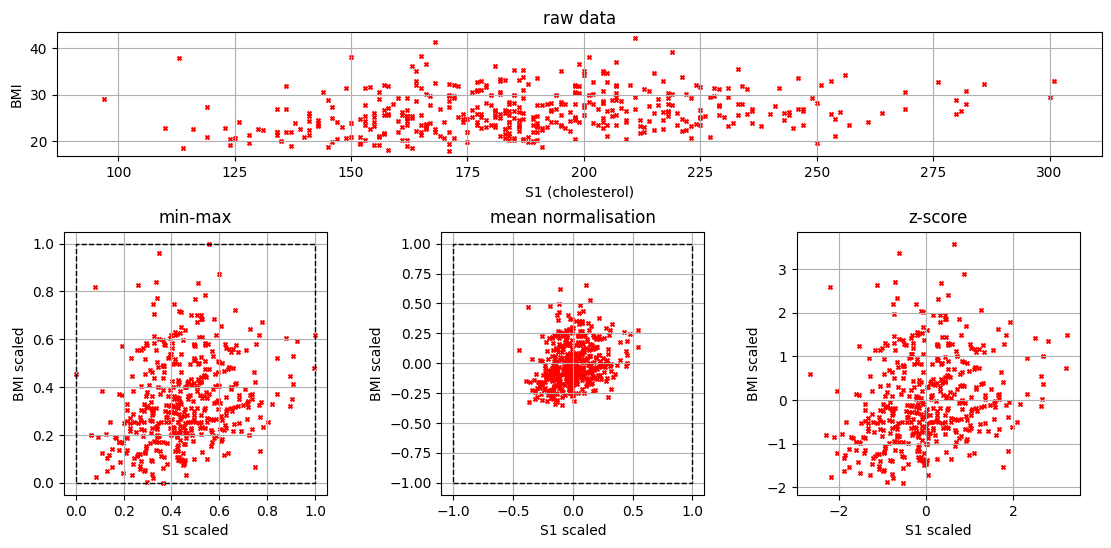

In [8]:
j1, j2 = feature_names.index('s1'), feature_names.index('bmi')
scaled_versions = [("min-max", min_max_scale(X_train)[0], [0, 1]),
                   ("mean normalisation", mean_normalise(X_train)[0], [-1, 1]),
                   ("z-score", X_norm, None)]

fig = plt.figure(figsize=(11, 6), constrained_layout=True)
ax0 = fig.add_subplot(2, 1, 1)
ax0.scatter(X_train[:, j1], X_train[:, j2], s=8, c='r', marker='x')
ax0.set(xlabel='S1 (cholesterol)', ylabel='BMI', title='raw data')
ax0.set_aspect('equal')
ax0.grid(True)
for k, (title, Xs, box) in enumerate(scaled_versions):
    a = fig.add_subplot(2, 3, 4 + k)
    a.scatter(Xs[:, j1], Xs[:, j2], s=8, c='r', marker='x')
    if box is not None:
        lo, hi = box
        a.plot([lo, hi, hi, lo, lo], [lo, lo, hi, hi, lo], 'k--', lw=1)
    a.set(xlabel='S1 scaled', ylabel='BMI scaled', title=title)
    a.set_aspect('equal')
    a.grid(True)
plt.show()

## Gradient descent with scaled features

We now run gradient descent on the z-score scaled features. With scaled features, a learning rate around $0.1$ to $0.3$ is a good start; here we use $\alpha = 0.3$.

In [9]:
w_norm, b_norm, J_hist_norm = gradient_descent(X_norm, y_train, alpha=0.3, n_iters=10_000)
gap = (J_hist_norm - J_min) / J_min
print(f"within 0.1% of J_min after {np.argmax(gap < 1e-3)} iterations")
print(f"after 10,000 iterations: J = {J_hist_norm[-1]:.4f}, J_min = {J_min:.4f}")

within 0.1% of J_min after 401 iterations
after 10,000 iterations: J = 1429.8482, J_min = 1429.8482


Scaling does not change the smallest possible cost $J_{\min}$, because the scaled features describe the same data in different units (see the next section). So we can compare both learning curves directly:

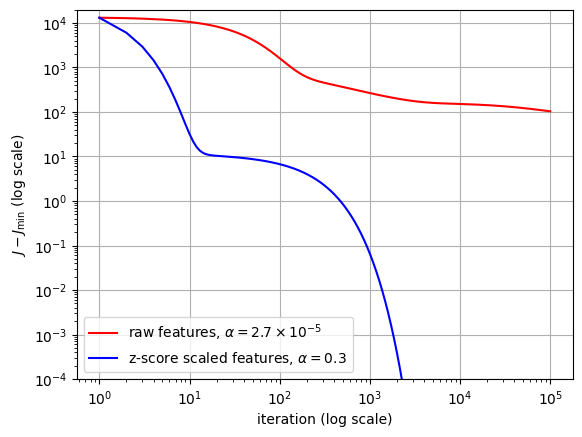

In [10]:
t_raw = np.arange(1, len(J_hist_raw) + 1)
t_norm = np.arange(1, len(J_hist_norm) + 1)
plt.loglog(t_raw, J_hist_raw - J_min, 'r-', label='raw features, $\\alpha = 2.7\\times 10^{-5}$')
plt.loglog(t_norm, J_hist_norm - J_min, 'b-', label='z-score scaled features, $\\alpha = 0.3$')
plt.xlabel('iteration (log scale)')
plt.ylabel('$J - J_{\\min}$ (log scale)')
plt.ylim(1e-4, 2e4)
plt.legend()
plt.grid(True)
plt.show()

With scaled features gradient descent is within $0.1\%$ of the minimum after about $400$ iterations; with raw features it is still $7\%$ above it after $100\,000$. This reproduces the lecture's figure. The scaled problem is not perfectly round either: some blood measurements are strongly correlated (e.g. S1 and S2), so the last digits still take a few thousand iterations.

## Same model, different units

Scaling only changes the units in which the features are measured; the fitted model is the same. Inserting $x_{j,\text{scaled}} = (x_j - \mu_j)/\sigma_j$ into the model gives
$$
\sum_{j=1}^{n} w_j\,\frac{x_j - \mu_j}{\sigma_j} + b
= \sum_{j=1}^{n} \underbrace{\frac{w_j}{\sigma_j}}_{w_{j,\text{raw}}}\,x_j
+ \underbrace{\Big(b - \sum_{j=1}^{n}\frac{w_j\,\mu_j}{\sigma_j}\Big)}_{b_\text{raw}} .
$$
So we can convert the weights learned on the scaled features back to the original units and compare them with scikit-learn, which was fitted on the raw features:

In [11]:
w_back = w_norm / sigma
b_back = b_norm - np.sum(w_norm * mu / sigma)
print(f"converted back: b = {b_back:.3f}\n  w = {w_back}")
print(f"scikit-learn:   b = {model.intercept_:.3f}\n  w = {model.coef_}")

converted back: b = -334.567
  w = [ -0.036 -22.86    5.603   1.117  -1.09    0.746   0.372   6.534  68.483
   0.28 ]
scikit-learn:   b = -334.567
  w = [ -0.036 -22.86    5.603   1.117  -1.09    0.746   0.372   6.534  68.483
   0.28 ]


## Predicting for a new patient

::: {.callout-important title="Use the training statistics"}
A model trained on scaled features expects scaled inputs. A new example must be scaled with the **same** $\boldsymbol\mu$ and $\boldsymbol\sigma$ that were computed on the training set, never with statistics of the new data.
:::

In [12]:
# age, sex, bmi, bp, s1, s2, s3, s4, s5, s6
x_new = np.array([50, 1, 28.0, 95, 190, 115, 48, 4.0, 4.6, 90])
x_new_scaled = (x_new - mu) / sigma          # training mu and sigma!
y_new = x_new_scaled @ w_norm + b_norm
print(f"prediction (scaled model):      {y_new:.2f}")
print(f"prediction (scikit-learn, raw): {model.predict(x_new.reshape(1, -1))[0]:.2f}")

prediction (scaled model):      166.70
prediction (scikit-learn, raw): 166.70


## Checking gradient descent and choosing $\alpha$

### Learning curves for different learning rates

The lecture suggests trying learning rates that grow by a factor of about 3. We run $300$ iterations for each and plot the learning curves.

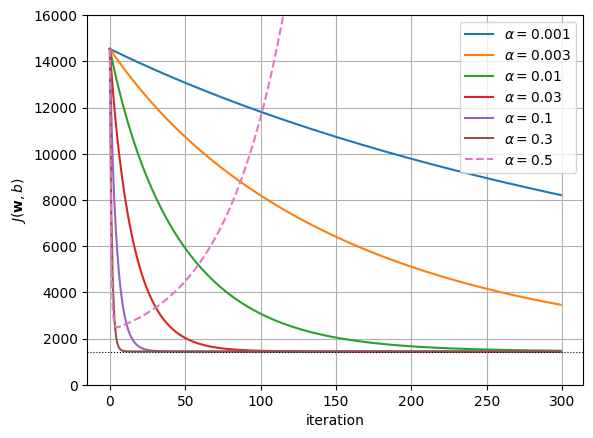

In [13]:
for alpha in [0.001, 0.003, 0.01, 0.03, 0.1, 0.3, 0.5]:
    _, _, J_hist = gradient_descent(X_norm, y_train, alpha=alpha, n_iters=300)
    style = '--' if alpha == 0.5 else '-'
    plt.plot(J_hist, style, label=f'$\\alpha = {alpha}$')
plt.axhline(J_min, color='k', lw=0.8, ls=':')
plt.ylim(0, 16000)
plt.xlabel('iteration')
plt.ylabel('$J(\\mathbf{w}, b)$')
plt.legend(loc='upper right')
plt.grid(True)
plt.show()

- For $\alpha = 0.001$ and $0.003$, $J$ decreases slowly: **increase** $\alpha$.
- For $\alpha = 0.5$, $J$ first decreases and then grows without bound. The stability limit for these data is about $0.497$; $\alpha = 0.5$ is just above it.
- Pick the largest $\alpha$ for which $J$ decreases quickly and steadily: here $\alpha = 0.3$.

### When the learning curve looks wrong

$J$ must decrease at every iteration. If it goes up, the two usual causes are

- **$\alpha$ too large**, as for $\alpha = 0.5$ above: use a smaller $\alpha$;
- **a bug**, for example `w = w + alpha * dJ_dw` instead of `w - ...` (Challenge 1 of Lab 3).

A useful debugging rule: with a sufficiently small $\alpha$, $J$ **must** decrease at every iteration. If it does not, look for a bug.

## Feature scaling with scikit-learn

`StandardScaler` performs z-score normalisation. `fit` computes $\boldsymbol\mu$ and $\boldsymbol\sigma$ from the training data and stores them in `mean_` and `scale_`; `transform` applies them; `fit_transform` does both. New data are only transformed, never fitted.

In [14]:
scaler = StandardScaler()
X_norm_sk = scaler.fit_transform(X_train)            # learn mu, sigma on the training data
print(f"same scaled data:  {np.allclose(X_norm_sk, X_norm)}")
print(f"same mu and sigma: {np.allclose(scaler.mean_, mu)}, {np.allclose(scaler.scale_, sigma)}")
print(f"scaled new patient: {scaler.transform(x_new.reshape(1, -1))}")

same scaled data:  True
same mu and sigma: True, True
scaled new patient: [[ 0.113 -0.939  0.368  0.026  0.025 -0.014 -0.138 -0.054 -0.079 -0.11 ]]


`MinMaxScaler` works in the same way for min-max normalisation.

## Challenges

1. Run gradient descent on the raw features with $\alpha = 3\times 10^{-5}$. What happens?
2. Repeat the comparison of learning curves with min-max scaled features instead of z-score scaled features. What is now the largest stable learning rate, and how many iterations are needed to get within $0.1\%$ of $J_{\min}$?
3. Add an **automatic convergence test** to `gradient_descent`: stop as soon as $J$ decreases by less than $\varepsilon = 10^{-3}$ in one iteration, and return the number of iterations used. How many iterations does it take with $\alpha = 0.3$ on the scaled data?

## Summary

- Features on very different scales make gradient descent extremely slow: the cost is a long, narrow valley.
- Min-max, mean and z-score normalisation bring all features to similar ranges; z-score (`StandardScaler`) is the most common choice.
- Scaling changes the units of the features, not the fitted model: the weights can be converted back.
- Compute the scaling statistics on the training set only, store them, and apply them to every new example.
- Plot learning curves: $J$ must decrease at every iteration. Try $\alpha = 0.001, 0.003, 0.01, \dots$ and pick the largest value that decreases $J$ quickly and steadily.